<img src="https://raw.githubusercontent.com/Brainchip-Inc/brainchip_devhub/main/docs/assets/0.-BC-dev-hub-LOGO-flicker.svg" alt="BrainChip Dev Hub" width="200"/>

# Hand Gesture Recognition (Jester) — Akida 2 Benchmark

Run Time: ~35 minutes

This notebook benchmarks BrainChip's **TENN spatiotemporal** model for hand gesture
recognition on **Jester**, on Akida 2 hardware. It measures the latency **per frame** in
each mapping mode, shows how the model maps onto the neural processors (NPs), and breaks
the time down layer by layer.

The model is a streaming one: it takes one frame per inference and gives a prediction
every frame. So the latency that matters is that of a single frame, which is how far the
prediction lags behind the live video.

For details on the model and the dataset, and on how the Akida model is produced, see the
neighboring README.md and jester_notebook_evaluation.ipynb.

> **Note:** the hardware benchmark needs a physical Akida 2 FPGA. Every hardware cell is
> guarded, so the notebook runs end to end without one (on Colab, for instance), but those
> cells are skipped and no latency is measured.

In [1]:
# Colab-only setup. Local users: ignore this cell - it does nothing for you.
import sys
if 'google.colab' in sys.modules:
    !wget -q https://raw.githubusercontent.com/Brainchip-Inc/brainchip_devhub/main/akida2/model_zoo/jester/colab_setup.py
import colab_setup
colab_setup.setup()

Not running on Colab — nothing to do. (This step only matters for Colab; local runs already have everything they need.)


## Configuration

`DATA_PATH = None` uses the BrainChip Jester subset, downloaded into `data/` on first use.
`NUM_CLIPS` sets how many consecutive clips are streamed through the model: each clip is
16 frames, and every frame is one timed inference.

In [2]:
import numpy as np
import akida

from brainchip_utils.hardware_utils import AKIDA_CLOCKS_HZ

DATA_PATH = None     # None: the BrainChip Jester subset, downloaded into data/
NUM_CLIPS = 10       # consecutive clips streamed by the benchmark (16 frames each)

# Clocks: see brainchip_utils.hardware_utils.AKIDA_CLOCKS_HZ
MEASURED_CLOCK = AKIDA_CLOCKS_HZ['AKIDA2_FPGA']  # 25 MHz FPGA
PROJECTED_CLOCK = AKIDA_CLOCKS_HZ['AKD2500']     # 1 GHz target (pre-production)

## Model

The converted Akida model is included in this repo, at
`pretrained_models/tenn_spatiotemporal_jester_buffer_i8_w8_a8.fbz`. Like every model file
in the repo, it is stored with Git LFS. If you haven't set that up yet, see the
[Trained models](../../../README.md#trained-models) section of the top-level README.
`verify_model` checks the file against its published sha256, so a text pointer left by a
missing `git lfs pull` fails here with a clear message.

To benchmark the model that `jester_eval.sh` writes to `models/` instead, use
`model_path('akida', 'models')` and skip `verify_model`.

In [3]:
from jester_model import model_path, verify_model

path = model_path('akida')
verify_model(path)
ak_model = akida.Model(str(path))
ak_model.summary()

                 Model Summary                  
________________________________________________
Input shape    Output shape  Sequences  Layers
[100, 100, 3]  [1, 1, 27]    1          18    
________________________________________________

_________________________________________________________________________
Layer (type)                            Output shape   Kernel shape    

================== SW/input_conv-dequantizer (Software) =================

input_conv (InputConv2D)                [50, 50, 8]    (3, 3, 3, 8)    
_________________________________________________________________________
convt_full_1_0 (BufferTempConv)         [50, 50, 20]   (1, 1, 40, 20)  
_________________________________________________________________________
convs_full_1_0 (Conv2D)                 [25, 25, 40]   (3, 3, 20, 40)  
_________________________________________________________________________
convt_full_2_0 (BufferTempConv)         [25, 25, 80]   (1, 1, 200, 80) 
__________________________

## Device

`get_akida_device` returns the first connected device whose IP version matches the
model's (Akida 2), or `None` if there isn't one. Without a device, the benchmark cells
below are skipped.

In [4]:
from brainchip_utils.hardware_utils import get_akida_device

device = get_akida_device(target_version=ak_model.ip_version)
if device is None:
    print('No compatible Akida hardware device found - the benchmark will be skipped.')
else:
    print('Akida device found:', device.desc)

Target Akida device found
Akida device found: fpga-1766


## Samples

Akida is event-driven: computation scales with the number of non-zero activations, so
timings depend on the input and the benchmark must use real frames. For a streaming model
the frames must also come **in order**, so that the temporal buffers hold real history.
The samples are the frames of consecutive clips, one after the other. The buffers are not
reset between clips during timing, as in a continuous stream.

In [5]:
from jester_data import get_data_dir, get_stream

samples = get_stream(get_data_dir(DATA_PATH), NUM_CLIPS)
print(f'{NUM_CLIPS} clips -> {samples.shape} {samples.dtype}')

105037345/105037345 [==============================] - 7s 0us/step
Download complete.
10 clips -> (160, 100, 100, 3) uint8


## Hardware check

Before timing, one clip is streamed frame by frame on the hardware and on the software
backend, each starting from empty buffers, and the outputs are compared. The software
backend is a bit-accurate simulation of the hardware, so the two should be identical.

In [6]:
from jester_benchmark import check_hw_matches_sw

if device is not None:
    print('Bit-identical:', check_hw_matches_sw(ak_model, device, samples[:16]))

Bit-identical: True


## Latency benchmark

`full_model_benchmark` from [brainchip_utils/hardware_utils.py](../../../brainchip_utils/hardware_utils.py)
runs one forward call per frame, so its mean latency is the latency per frame. It times the
model in each mapping mode:

- **Minimal** maps the model onto the fewest NPs.
- **AllNps** uses as many NPs as possible while keeping the minimum number of passes.
- **HwPr** (hardware partial reconfiguration) splits the model into more passes, so that
  each layer can use more NPs, and reloads the weights between passes on every inference.

The FPGA runs at **25 MHz**, so the latency **projected** to the 1 GHz AKD2500 target clock
is reported too: the cycle count of a model and mapping does not depend on the clock.

In [7]:
from brainchip_utils.hardware_utils import full_model_benchmark, get_mapping_stats

full_results = {}
if device is not None:
    for mm in ['Minimal', 'AllNps', 'HwPr']:
        map_mode = getattr(akida.MapMode, mm)
        res = full_model_benchmark(ak_model, device, samples, map_mode=map_mode,
                                   batch_size=1, clock_freq=MEASURED_CLOCK)
        if res is None:
            print(f'[{mm}] does not map onto this device - skipped')
            continue
        res['projected_clk_ms'] = res['mean_inf_clk'] / PROJECTED_CLOCK * 1000
        ak_model.map(device, mode=map_mode)
        res['num_nps'], res['num_passes'], _ = get_mapping_stats(ak_model)
        full_results[mm] = res
        print(f"[{mm}] {res['num_nps']} NPs, {res['num_passes']} passes: "
              f"{res['mean_clk_ms']:.3f} ms per frame @ 25 MHz, "
              f"{res['projected_clk_ms']:.3f} ms projected @ 1 GHz")

Power measurement not available: only supported on AKD1500 (IpVersion.v1).
  Repeat 1/10 done.
  Repeat 2/10 done.
  Repeat 3/10 done.
  Repeat 4/10 done.
  Repeat 5/10 done.
  Repeat 6/10 done.
  Repeat 7/10 done.
  Repeat 8/10 done.
  Repeat 9/10 done.
  Repeat 10/10 done.

  Mean inference time:    218.666 ms  (σ=6.261 ms)
  Mean on-chip time:      209.324 ms  (5233100 clocks)
  Total inferences run:   1600
[Minimal] 44 NPs, 2 passes: 209.324 ms per frame @ 25 MHz, 5.233 ms projected @ 1 GHz
Power measurement not available: only supported on AKD1500 (IpVersion.v1).
  Repeat 1/10 done.
  Repeat 2/10 done.
  Repeat 3/10 done.
  Repeat 4/10 done.
  Repeat 5/10 done.
  Repeat 6/10 done.
  Repeat 7/10 done.
  Repeat 8/10 done.
  Repeat 9/10 done.
  Repeat 10/10 done.

  Mean inference time:    218.460 ms  (σ=6.260 ms)
  Mean on-chip time:      209.118 ms  (5227952 clocks)
  Total inferences run:   1600
[AllNps] 45 NPs, 2 passes: 209.118 ms per frame @ 25 MHz, 5.228 ms projected @ 1 GHz
P

The plot shows the NPs each layer uses in each mapping mode, and where the pass
boundaries fall.

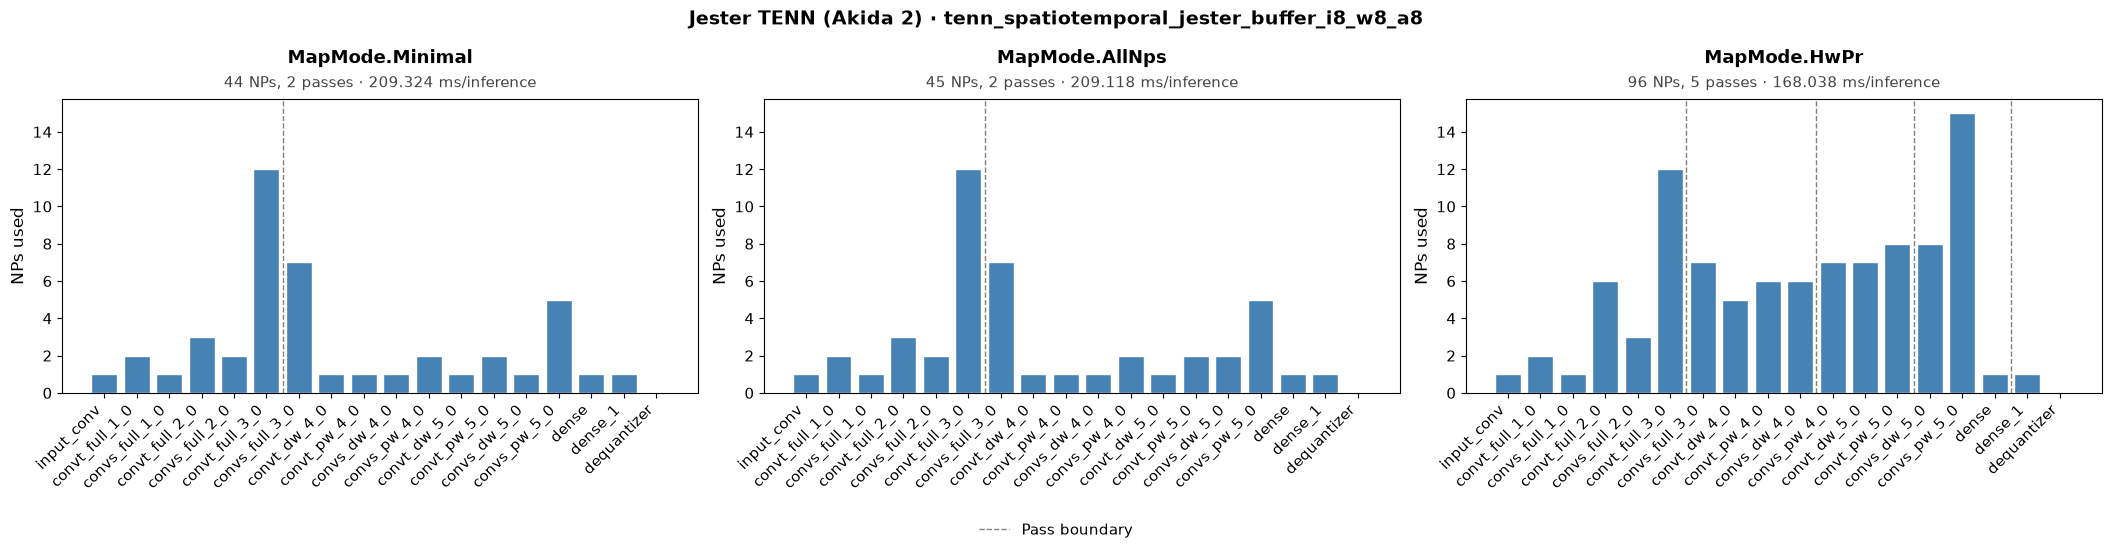

In [8]:
from brainchip_utils.plot_utils import plot_full_model_results

if full_results:
    ak_model.map(device, mode=akida.MapMode.Minimal)
    plot_full_model_results(full_results, ak_model, device,
                            model_name=path.name, example='Jester TENN (Akida 2)',
                            show_power=False)

## Per-layer benchmark and sparsity

`per_layer_benchmark` reconstructs the latency layer by layer, by timing cumulative
sub-models on the same frame stream and taking the differences. `stream_sparsity` (from
`jester_eval.py`) measures each layer's activation sparsity over the stream, one frame per
call. Sparsity is computed on the software backend, so it is available without a device too.

In [9]:
from brainchip_utils.hardware_utils import per_layer_benchmark
from brainchip_utils.plot_utils import pretty_print_sparsity
from jester_eval import stream_sparsity

sparsity_dict = stream_sparsity(ak_model, samples)
pretty_print_sparsity(sparsity_dict)

per_layer_results = None
if full_results:
    ak_model.map(device, mode=akida.MapMode.Minimal, hw_only=True)
    per_layer_results = per_layer_benchmark(ak_model, device, samples,
                                            repeats=len(samples), clock_freq=MEASURED_CLOCK)


Layer              Sparsity
---------------------------
input_conv          34.78%
convt_full_1_0      42.60%
convs_full_1_0      43.50%
convt_full_2_0      66.67%
convs_full_2_0      71.69%
convt_full_3_0      74.46%
convs_full_3_0      72.29%
convt_dw_4_0        59.18%
convt_pw_4_0        50.23%
convs_dw_4_0        45.46%
convs_pw_4_0        66.39%
convt_dw_5_0        45.42%
convt_pw_5_0        55.23%
convs_dw_5_0        39.59%
convs_pw_5_0        92.23%
dense               99.13%
dense_1              0.00%
---------------------------
Mean                56.40%

Layer              Latency (ms)       Clocks
------------------------------------
input_conv               0.8198
convt_full_1_0          20.8465
convs_full_1_0          40.3146
convt_full_2_0          43.0287
convs_full_2_0          38.2751
convt_full_3_0          16.8656
convs_full_3_0          13.8589
convt_dw_4_0             4.2128
convt_pw_4_0             6.6899
convs_dw_4_0             0.9064
convs_pw_4_0             3

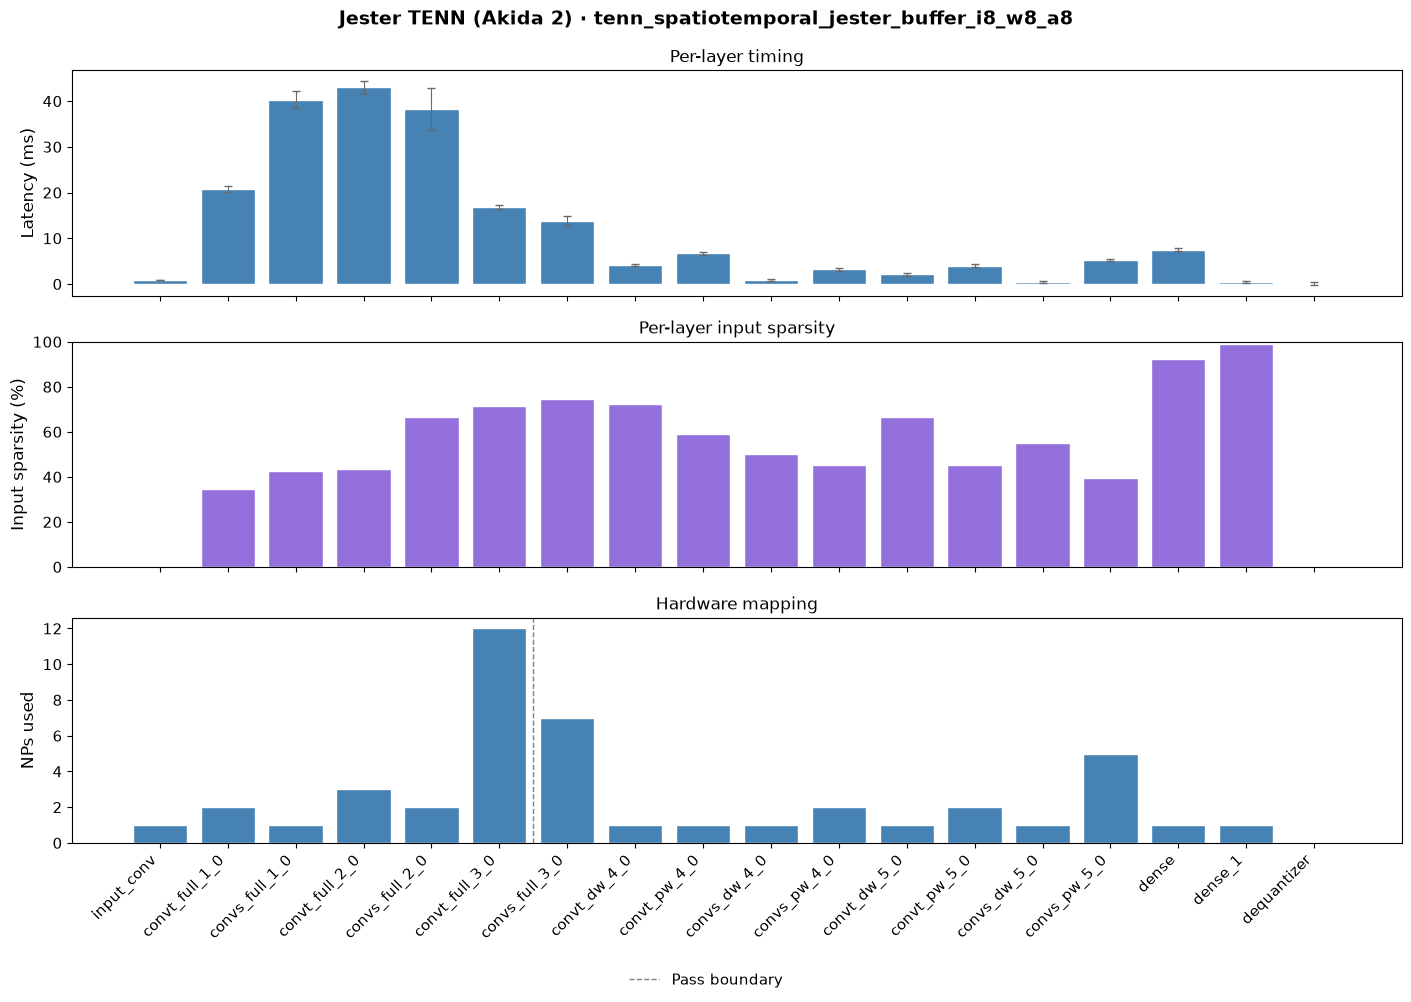

In [10]:
from brainchip_utils.plot_utils import plot_per_layer_results

if per_layer_results is not None:
    # Map without hw_only so the mapping plot can be drawn
    ak_model.map(device, mode=akida.MapMode.Minimal)
    plot_per_layer_results(per_layer_results, ak_model, sparsity_dict,
                           model_name=path.name, example='Jester TENN (Akida 2)')

## Summary

The latency per frame in each mapping mode, measured on the FPGA and projected to the
AKD2500 target clock. The README discusses what the three modes show for this model.

In [11]:
print(f'Jester TENN, 100 x 100 frames, 8-bit; {len(samples)} streamed frames')
print(f'  mean activation sparsity: {np.mean(list(sparsity_dict.values())) * 100:.2f}%')
for mm, res in full_results.items():
    print(f"  {mm:8} {res['num_nps']:3d} NPs, {res['num_passes']:2d} passes, "
          f"{res['mean_clk_ms']:8.3f} ms per frame @ 25 MHz, "
          f"{res['projected_clk_ms']:6.3f} ms projected @ 1 GHz")

Jester TENN, 100 x 100 frames, 8-bit; 160 streamed frames
  mean activation sparsity: 56.40%
  Minimal   44 NPs,  2 passes,  209.324 ms per frame @ 25 MHz,  5.233 ms projected @ 1 GHz
  AllNps    45 NPs,  2 passes,  209.118 ms per frame @ 25 MHz,  5.228 ms projected @ 1 GHz
  HwPr      96 NPs,  5 passes,  168.038 ms per frame @ 25 MHz,  4.201 ms projected @ 1 GHz
